# Heart Disease Detection with Neural Networks: NumPy from Scratch vs TensorFlow/Keras

Binary classification of heart disease presence from 13 clinical attributes. The project builds a neural network from first principles in NumPy (forward pass, binary cross-entropy, backpropagation and gradient descent), reproduces it in TensorFlow/Keras, compares the two, runs a small hyperparameter study, and closes with a reflection on fairness and ethics in clinical machine learning.

**Author:** Jyothi Kodenkiri

## Problem statement

Heart disease is a leading cause of death worldwide, and early identification of at-risk patients supports timely diagnosis and treatment. Using a heart disease dataset of patient clinical measurements, the objective is to:

1. **Prepare and analyse the data:** profile it, check quality, visualise the target and key features, and create leak-free train/validation/test splits.
2. **Build a neural network from scratch in NumPy:** implement the forward pass, binary cross-entropy loss, backpropagation and gradient-descent updates, and track loss and accuracy.
3. **Implement the same task in TensorFlow/Keras:** build a comparable model, try a second configuration (different activation and optimiser) and compare against the NumPy model.
4. **Analyse hyperparameters:** run a small search over learning rate, hidden-layer size and optimiser, and explain what changed and why.
5. **Reflect** on the modelling approaches, a bias/fairness/ethics concern, how pipeline choices affect it, a mitigation, and the key lessons about deep learning fundamentals.

### Data dictionary

| Feature | Description |
| --- | --- |
| `age` | Age in years |
| `sex` | 1 = male, 0 = female |
| `cp` | Chest pain type (0–3) |
| `trestbps` | Resting blood pressure (mm Hg) |
| `chol` | Serum cholesterol (mg/dl) |
| `fbs` | Fasting blood sugar > 120 mg/dl (1 = true) |
| `restecg` | Resting electrocardiographic result (0–2) |
| `thalach` | Maximum heart rate achieved |
| `exang` | Exercise-induced angina (1 = yes) |
| `oldpeak` | ST depression induced by exercise relative to rest |
| `slope` | Slope of the peak exercise ST segment (0–2) |
| `ca` | Number of major vessels coloured by fluoroscopy (0–4) |
| `thal` | Thalassemia result (0–3) |
| `target` | **1 = heart disease, 0 = no heart disease** |

## Environment setup

In [1]:
# Uncomment in Google Colab if any package is missing
# !pip install -q numpy pandas matplotlib seaborn scikit-learn tensorflow

import os, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, optimizers, metrics

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [2]:
def evaluate_model(y_true, y_pred, y_proba, name):
    """Print and return the standard binary-classification metrics for one model."""
    y_true = np.ravel(y_true); y_pred = np.ravel(y_pred); y_proba = np.ravel(y_proba)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_proba)
    print(f"--- {name} ---")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f} | ROC-AUC: {auc:.4f}")
    return {"model": name, "accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "roc_auc": auc}

# Part 1: Data Preparation and Analysis

### 1.1 Load the dataset and preview its structure

In [3]:
# Works from the repository root or from the notebooks/ folder
candidate_paths = [Path("data/heart.csv"), Path("../data/heart.csv"), Path("heart.csv")]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Dataset not found. Tried: {[str(p) for p in candidate_paths]}")

df_raw = pd.read_csv(DATA_PATH)
TARGET_COL = "target"
print(f"Shape: {df_raw.shape}")
display(df_raw.head())
df_raw.info()

Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


### 1.2 Statistical summary, missing values and duplicates

In [4]:
display(df_raw.describe().T.round(2))

missing = df_raw.isna().sum()
print(f"Missing values in the whole dataset: {missing.sum()}")

n_dup = df_raw.duplicated().sum()
print(f"Exact duplicate rows: {n_dup} of {len(df_raw)} ({n_dup / len(df_raw):.1%})")
print(f"Unique patient records: {len(df_raw.drop_duplicates())}")

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.43,9.07,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.70,0.46,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.94,1.03,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.61,17.52,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.00,51.59,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.53,0.53,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.11,23.01,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.34,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.07,1.18,0.0,0.0,0.8,1.8,6.2


Missing values in the whole dataset: 0
Exact duplicate rows: 723 of 1025 (70.5%)
Unique patient records: 302


**Data quality finding: duplicate records.** The file contains 1,025 rows, but only 302 are unique; the remaining 723 rows are exact copies of existing records. If duplicates are kept, copies of the same patient end up in both the training and the test sets, so the model is partly evaluated on patients it has already seen. That inflates every reported metric. The duplicates are therefore removed **before** any splitting, so the evaluation reflects genuinely unseen patients.

In [5]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Rows after removing duplicates: {len(df)}")

Rows after removing duplicates: 302


### 1.3 Target balance and key feature distributions

target
1    0.543
0    0.457
Name: proportion, dtype: float64


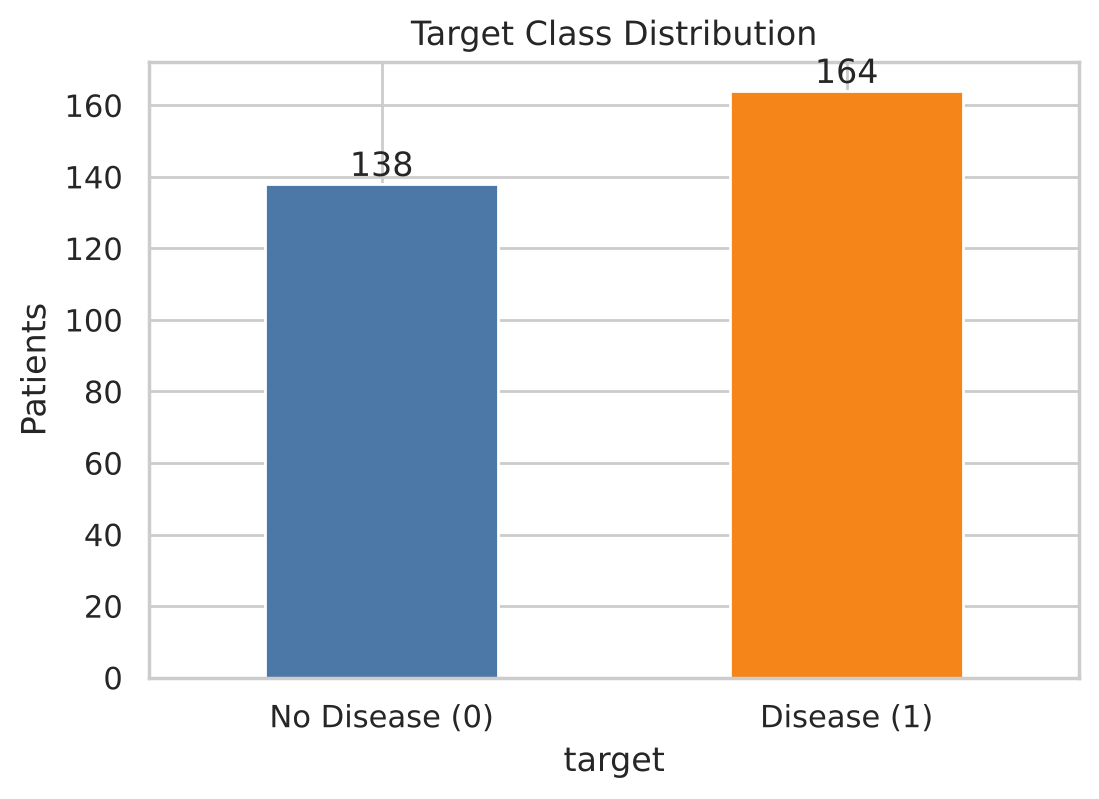

In [6]:
CONTINUOUS = ["age", "trestbps", "chol", "thalach", "oldpeak"]
BINARY = ["sex", "fbs", "exang"]
CATEGORICAL = ["cp", "restecg", "slope", "ca", "thal"]

counts = df[TARGET_COL].value_counts().sort_index()
print(df[TARGET_COL].value_counts(normalize=True).rename("proportion").round(3))

ax = counts.plot(kind="bar", color=["#4C78A8", "#F58518"], figsize=(6, 4))
ax.set_xticklabels(["No Disease (0)", "Disease (1)"], rotation=0)
ax.bar_label(ax.containers[0])
ax.set_title("Target Class Distribution")
ax.set_ylabel("Patients")
plt.show()

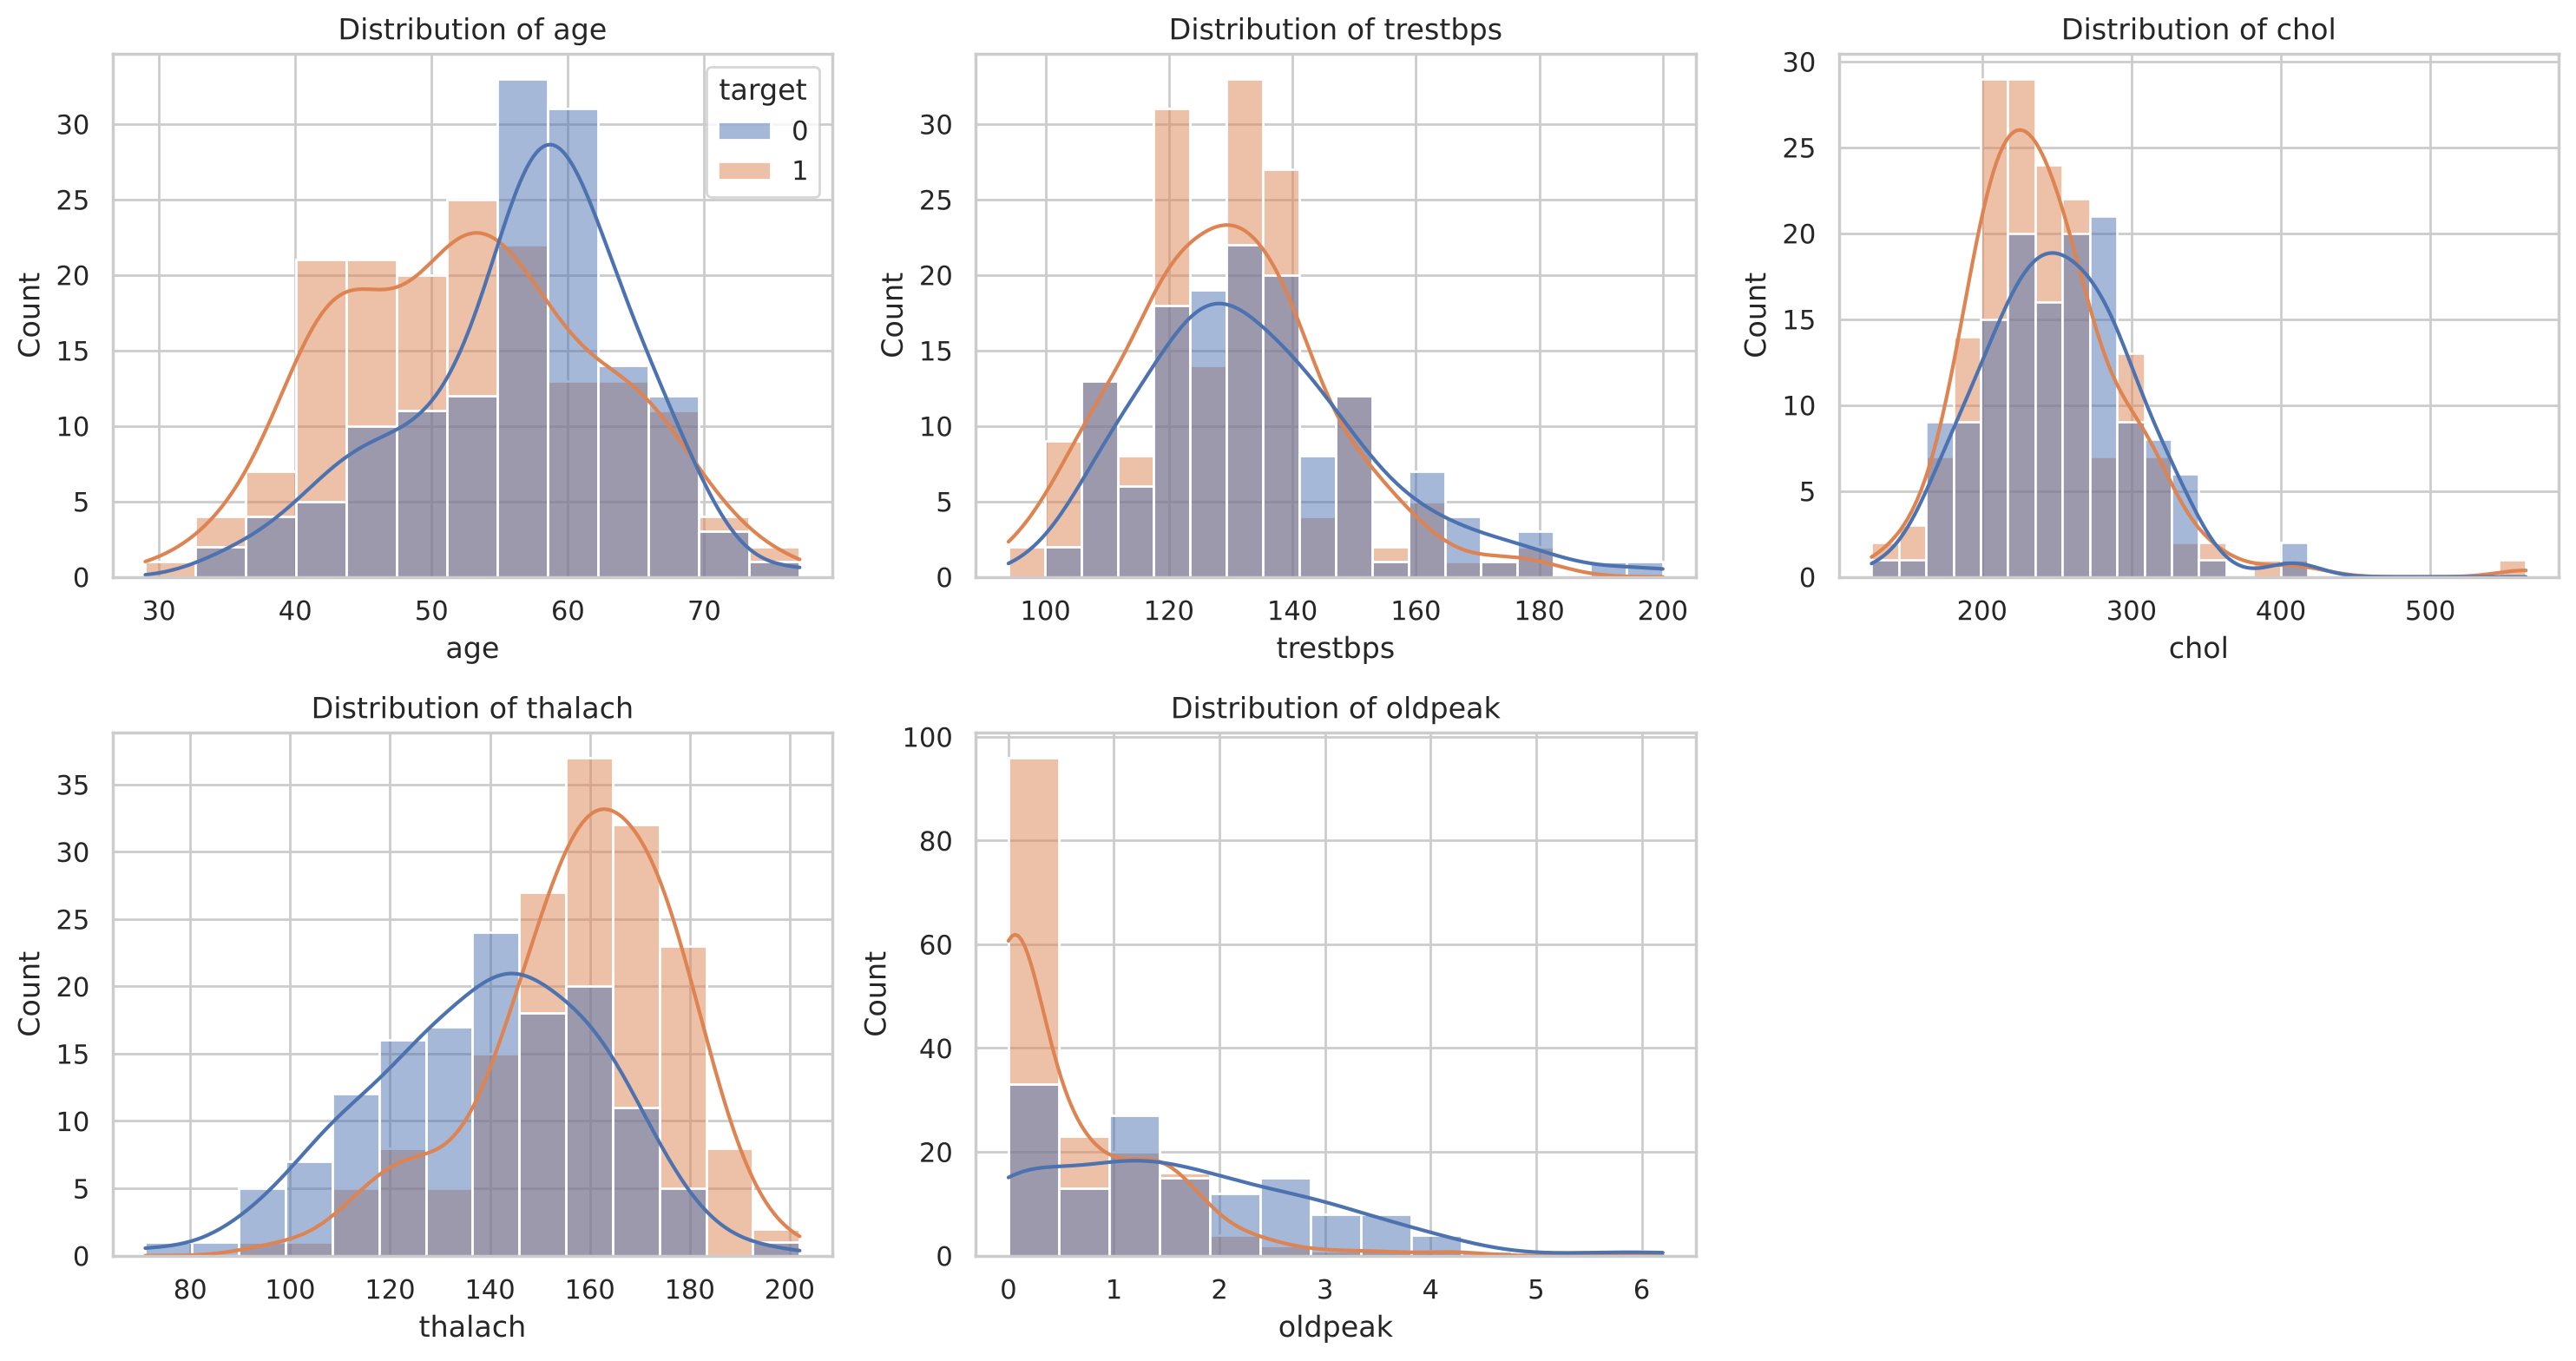

In [7]:
# Continuous features by target
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), CONTINUOUS):
    sns.histplot(data=df, x=col, hue=TARGET_COL, kde=True, ax=ax,
                 palette=["#4C72B0", "#DD8452"], legend=(col == "age"))
    ax.set_title(f"Distribution of {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

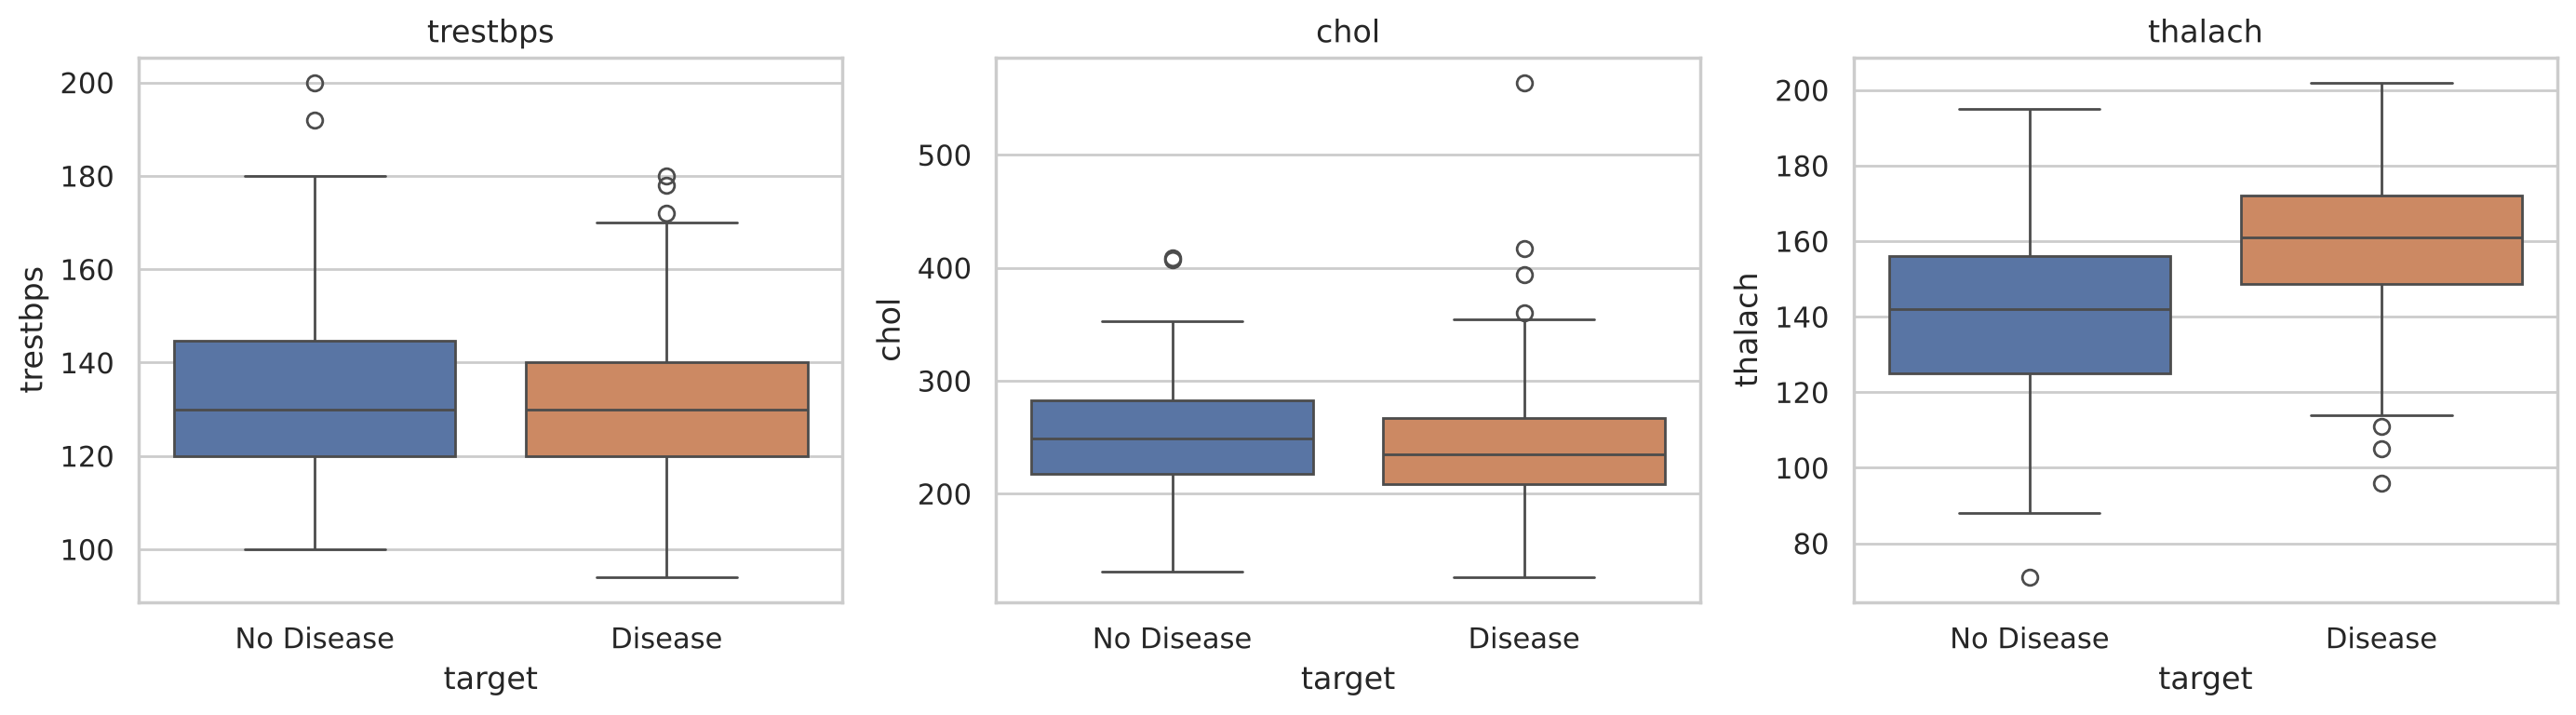

In [8]:
# Clinical measurements by target
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["trestbps", "chol", "thalach"]):
    sns.boxplot(data=df, x=TARGET_COL, y=col, ax=ax, hue=TARGET_COL,
                palette=["#4C72B0", "#DD8452"], legend=False)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["No Disease", "Disease"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

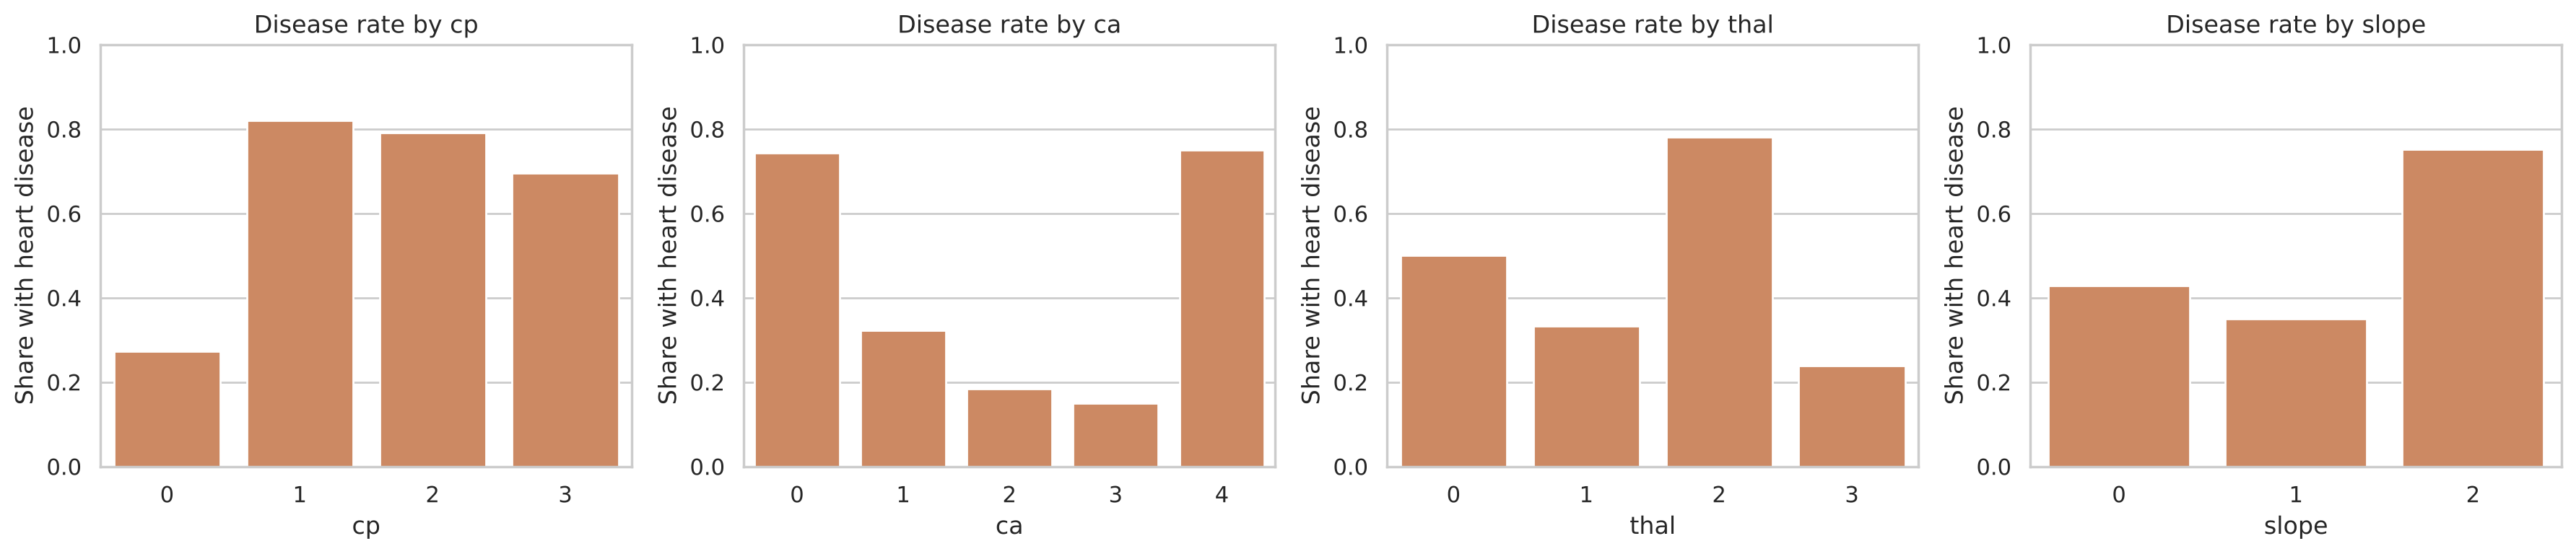

In [9]:
# Categorical features: disease rate per category
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["cp", "ca", "thal", "slope"]):
    rate = df.groupby(col)[TARGET_COL].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#DD8452")
    ax.set_title(f"Disease rate by {col}")
    ax.set_xlabel(col); ax.set_ylabel("Share with heart disease"); ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

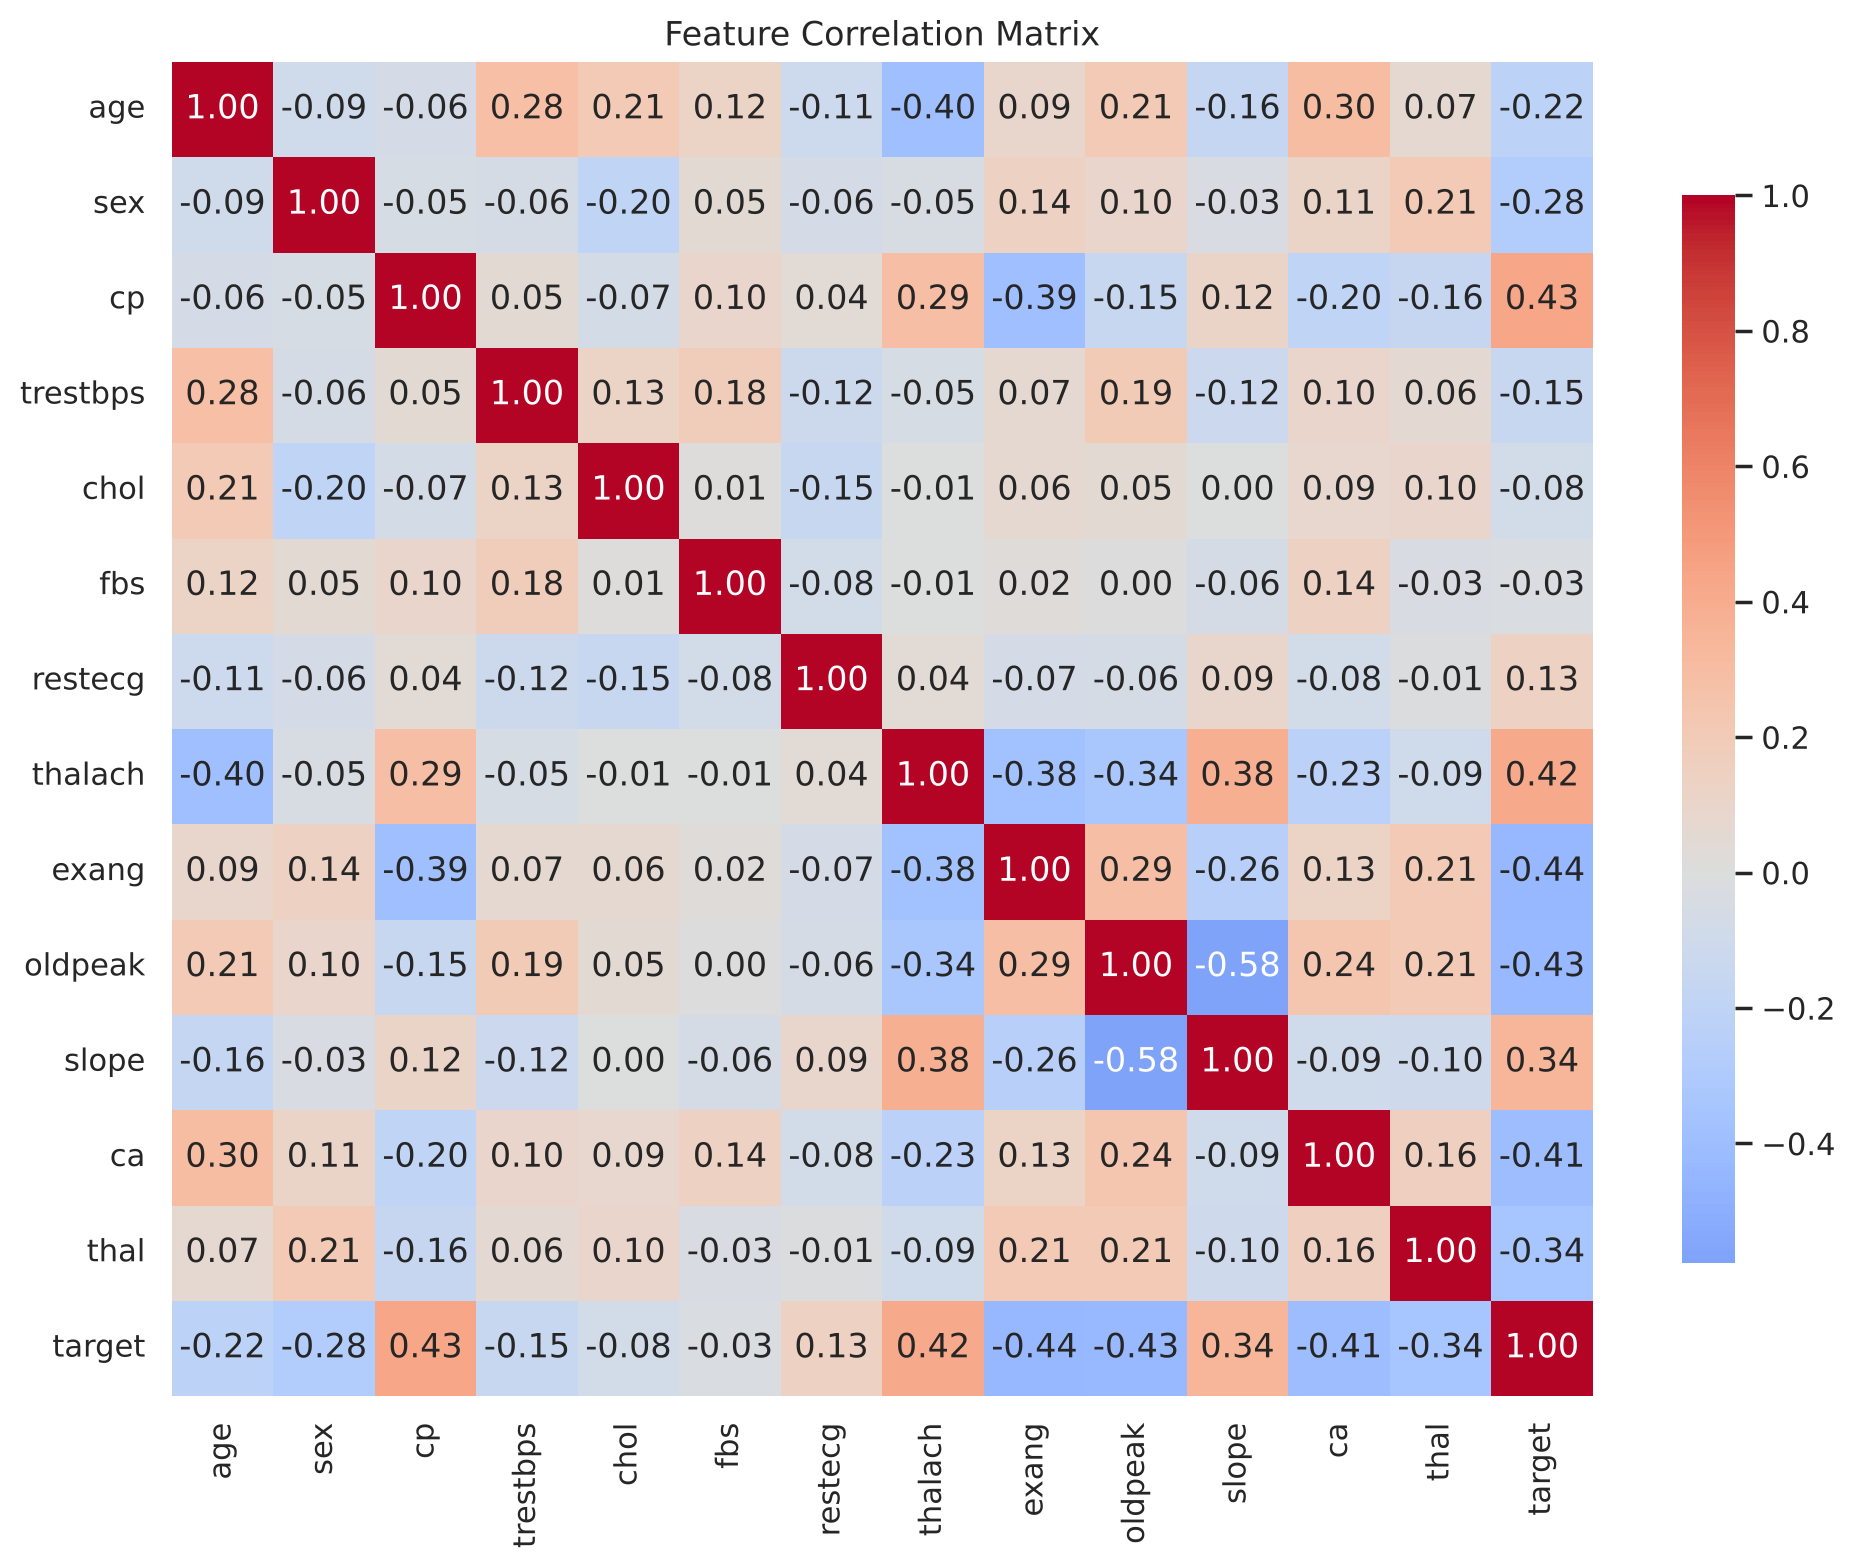

Correlation with target (sorted):
exang      -0.436
oldpeak    -0.429
ca         -0.409
thal       -0.343
sex        -0.284
age        -0.221
trestbps   -0.146
chol       -0.081
fbs        -0.027
restecg     0.135
slope       0.344
thalach     0.420
cp          0.432
Name: target, dtype: float64


In [10]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

print("Correlation with target (sorted):")
print(corr[TARGET_COL].drop(TARGET_COL).sort_values().round(3))

### Key observations from the exploratory analysis

- After deduplication the classes are reasonably balanced: 164 patients with heart disease (54.3%) and 138 without (45.7%), so accuracy remains a meaningful metric alongside ROC-AUC.
- The features most strongly associated with the target are chest-pain type `cp` (+0.43), maximum heart rate `thalach` (+0.42), exercise-induced angina `exang` (−0.44), ST depression `oldpeak` (−0.43) and the number of major vessels `ca` (−0.41).
- Cholesterol (`chol`, −0.08) and fasting blood sugar (`fbs`, −0.03) have almost no linear relationship with the target in this dataset, despite their clinical reputation.
- The categorical codes show very different disease rates from one category to the next, which is why they are one-hot encoded rather than treated as continuous numbers.

### 1.4 Train / validation / test split (no leakage)

In [11]:
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL].astype(int)

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.2, random_state=SEED, stratify=y_tmp)

print("Split sizes  train / val / test:", len(X_train), len(X_val), len(X_test))
print("Disease share train / val / test:",
      round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))

Split sizes  train / val / test: 192 49 61
Disease share train / val / test: 0.542 0.551 0.541


### 1.5 Missing values, outliers, encoding and scaling (fitted on training data only)

In [12]:
# 1) Imputation policy: no values are missing, but the pipeline keeps a fallback
#    (training-set median for numeric, training-set mode for categorical)
train_medians = X_train[CONTINUOUS + BINARY].median()
train_modes = X_train[CATEGORICAL].mode().iloc[0]

def impute(frame):
    frame = frame.copy()
    frame[CONTINUOUS + BINARY] = frame[CONTINUOUS + BINARY].fillna(train_medians)
    frame[CATEGORICAL] = frame[CATEGORICAL].fillna(train_modes)
    return frame

# 2) Outliers: IQR capping (winsorisation) on continuous measurements only.
#    Bounds are learned from the training split, then applied to every split.
q1, q3 = X_train[CONTINUOUS].quantile(0.25), X_train[CONTINUOUS].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

def cap(frame):
    frame = frame.copy()
    frame[CONTINUOUS] = frame[CONTINUOUS].clip(lower=lower, upper=upper, axis=1)
    return frame

capped = pd.DataFrame({
    "lower_bound": lower.round(2), "upper_bound": upper.round(2),
    "train_values_capped": [((X_train[c] < lower[c]) | (X_train[c] > upper[c])).sum() for c in CONTINUOUS],
})
display(capped)

X_train_p, X_val_p, X_test_p = (cap(impute(f)) for f in (X_train, X_val, X_test))

# 3) Encoding and scaling: one-hot encode nominal codes, standardise everything else.
preprocess = ColumnTransformer([
    ("num", StandardScaler(), CONTINUOUS + BINARY),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])
Xtr = preprocess.fit_transform(X_train_p).astype(np.float32)
Xva = preprocess.transform(X_val_p).astype(np.float32)
Xte = preprocess.transform(X_test_p).astype(np.float32)
ytr = y_train.to_numpy().reshape(-1, 1).astype(np.float32)
yva = y_val.to_numpy().reshape(-1, 1).astype(np.float32)
yte = y_test.to_numpy().reshape(-1, 1).astype(np.float32)

feature_names = preprocess.get_feature_names_out()
print(f"Model input features after encoding: {len(feature_names)}")
print("Array shapes:", Xtr.shape, Xva.shape, Xte.shape)

,lower_bound,upper_bound,train_values_capped
age,28.12,81.12,0
trestbps,90.00,170.00,5
chol,105.62,386.62,5
thalach,88.50,212.50,2
oldpeak,-2.25,3.75,5


Model input features after encoding: 27
Array shapes: (192, 27) (49, 27) (61, 27)


### Preprocessing decision log

- **Duplicates:** 723 exact duplicate rows were removed before splitting, leaving 302 unique patients. This is the single most important step for an honest evaluation, because duplicates shared across splits leak test patients into training.
- **Missing values:** none are present. As a safeguard, the pipeline still imputes with the **training-set median** for numeric fields and the **training-set mode** for categorical codes. The median is robust to skewed clinical readings, and the mode avoids inventing categories that do not exist.
- **Outliers:** extreme clinical values, such as resting blood pressure up to 200 mm Hg or cholesterol above 560 mg/dl, are handled with **IQR capping (winsorisation)**:

$$\text{Lower} = Q1 - 1.5 \times IQR \qquad \text{Upper} = Q3 + 1.5 \times IQR$$

  Capping is applied only to the five continuous measurements, with bounds learned from the training split. Categorical codes (`cp`, `ca`, `thal`, `slope`, `restecg`) are not capped, because their values are labels rather than magnitudes. Rows are never deleted, so the small cohort keeps all of its training signal. The trade-off is that genuine extreme readings are compressed, which could hide severe pathology markers.
- **Encoding and scaling:** nominal codes are one-hot encoded so that the network does not treat, for example, chest-pain type 3 as "three times" type 1. Continuous and binary features are standardised. Every transformer is fitted on the training split only and then applied to the validation and test splits.

# Part 2: Neural Network from Scratch (NumPy)

The network below is a fully connected feed-forward model with sigmoid activations, trained with mini-batch gradient descent. Every step (forward pass, binary cross-entropy loss, backpropagation and the weight update) is written by hand in NumPy.

In [13]:
class NumpyNeuralNetwork:
    """A fully connected feed-forward network with sigmoid activations,
    trained with mini-batch gradient descent, implemented from scratch in NumPy."""

    def __init__(self, layer_sizes, learning_rate=0.1, seed=42):
        # layer_sizes e.g. [n_features, 16, 1]
        self.layer_sizes = layer_sizes
        self.lr = learning_rate
        rng = np.random.RandomState(seed)
        self.W, self.b = [], []
        for i in range(len(layer_sizes) - 1):
            # Small random initialisation scaled by fan-in (limits sigmoid saturation)
            self.W.append(rng.randn(layer_sizes[i], layer_sizes[i + 1]) * np.sqrt(1.0 / layer_sizes[i]))
            self.b.append(np.zeros((1, layer_sizes[i + 1])))

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    @staticmethod
    def sigmoid_derivative(a):
        # a is already sigmoid(z)
        return a * (1 - a)

    def forward(self, X):
        activations, zs, A = [X], [], X
        for W, b in zip(self.W, self.b):
            Z = A @ W + b
            A = self.sigmoid(Z)
            zs.append(Z)
            activations.append(A)
        return activations, zs

    @staticmethod
    def binary_cross_entropy(y_true, y_pred, eps=1e-9):
        y_pred = np.clip(y_pred, eps, 1 - eps)
        return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

    def backward(self, activations, y):
        m, L = y.shape[0], len(self.W)
        grads_W, grads_b = [None] * L, [None] * L
        # Output error: BCE combined with the sigmoid derivative simplifies to (A_L - y)
        dA = activations[-1] - y
        for l in reversed(range(L)):
            A_prev = activations[l]
            dZ = dA if l == L - 1 else dA * self.sigmoid_derivative(activations[l + 1])
            grads_W[l] = (A_prev.T @ dZ) / m
            grads_b[l] = np.sum(dZ, axis=0, keepdims=True) / m
            if l > 0:
                dA = dZ @ self.W[l].T
        return grads_W, grads_b

    def update(self, grads_W, grads_b):
        for l in range(len(self.W)):
            self.W[l] -= self.lr * grads_W[l]
            self.b[l] -= self.lr * grads_b[l]

    def train(self, X, y, X_val=None, y_val=None, epochs=300, batch_size=32, verbose=True):
        history = {"loss": [], "val_loss": [], "val_acc": []}
        n = X.shape[0]
        rng = np.random.RandomState(0)
        for epoch in range(epochs):
            idx = rng.permutation(n)
            X_shuf, y_shuf = X[idx], y[idx]
            epoch_losses = []
            for start in range(0, n, batch_size):
                xb, yb = X_shuf[start:start + batch_size], y_shuf[start:start + batch_size]
                activations, _ = self.forward(xb)
                epoch_losses.append(self.binary_cross_entropy(yb, activations[-1]))
                self.update(*self.backward(activations, yb))
            history["loss"].append(np.mean(epoch_losses))
            if X_val is not None:
                val_pred = self.forward(X_val)[0][-1]
                history["val_loss"].append(self.binary_cross_entropy(y_val, val_pred))
                history["val_acc"].append(np.mean((val_pred > 0.5) == y_val))
            if verbose and (epoch % 50 == 0 or epoch == epochs - 1):
                msg = f"Epoch {epoch:4d} | train_loss={history['loss'][-1]:.4f}"
                if X_val is not None:
                    msg += f" | val_loss={history['val_loss'][-1]:.4f} | val_acc={history['val_acc'][-1]:.4f}"
                print(msg)
        return history

    def predict_proba(self, X):
        return self.forward(X)[0][-1]

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) > threshold).astype(int)

### Training the NumPy neural network

In [14]:
numpy_nn = NumpyNeuralNetwork(layer_sizes=[Xtr.shape[1], 16, 1], learning_rate=0.5, seed=SEED)
numpy_nn_history = numpy_nn.train(Xtr, ytr, X_val=Xva, y_val=yva, epochs=300, batch_size=32)

Epoch    0 | train_loss=0.7372 | val_loss=0.6827 | val_acc=0.5306
Epoch   50 | train_loss=0.2214 | val_loss=0.5765 | val_acc=0.7143
Epoch  100 | train_loss=0.1821 | val_loss=0.6767 | val_acc=0.6939
Epoch  150 | train_loss=0.1426 | val_loss=0.7445 | val_acc=0.7143


Epoch  200 | train_loss=0.0974 | val_loss=0.8344 | val_acc=0.7143
Epoch  250 | train_loss=0.0711 | val_loss=0.9373 | val_acc=0.7143


Epoch  299 | train_loss=0.0523 | val_loss=1.0308 | val_acc=0.7143


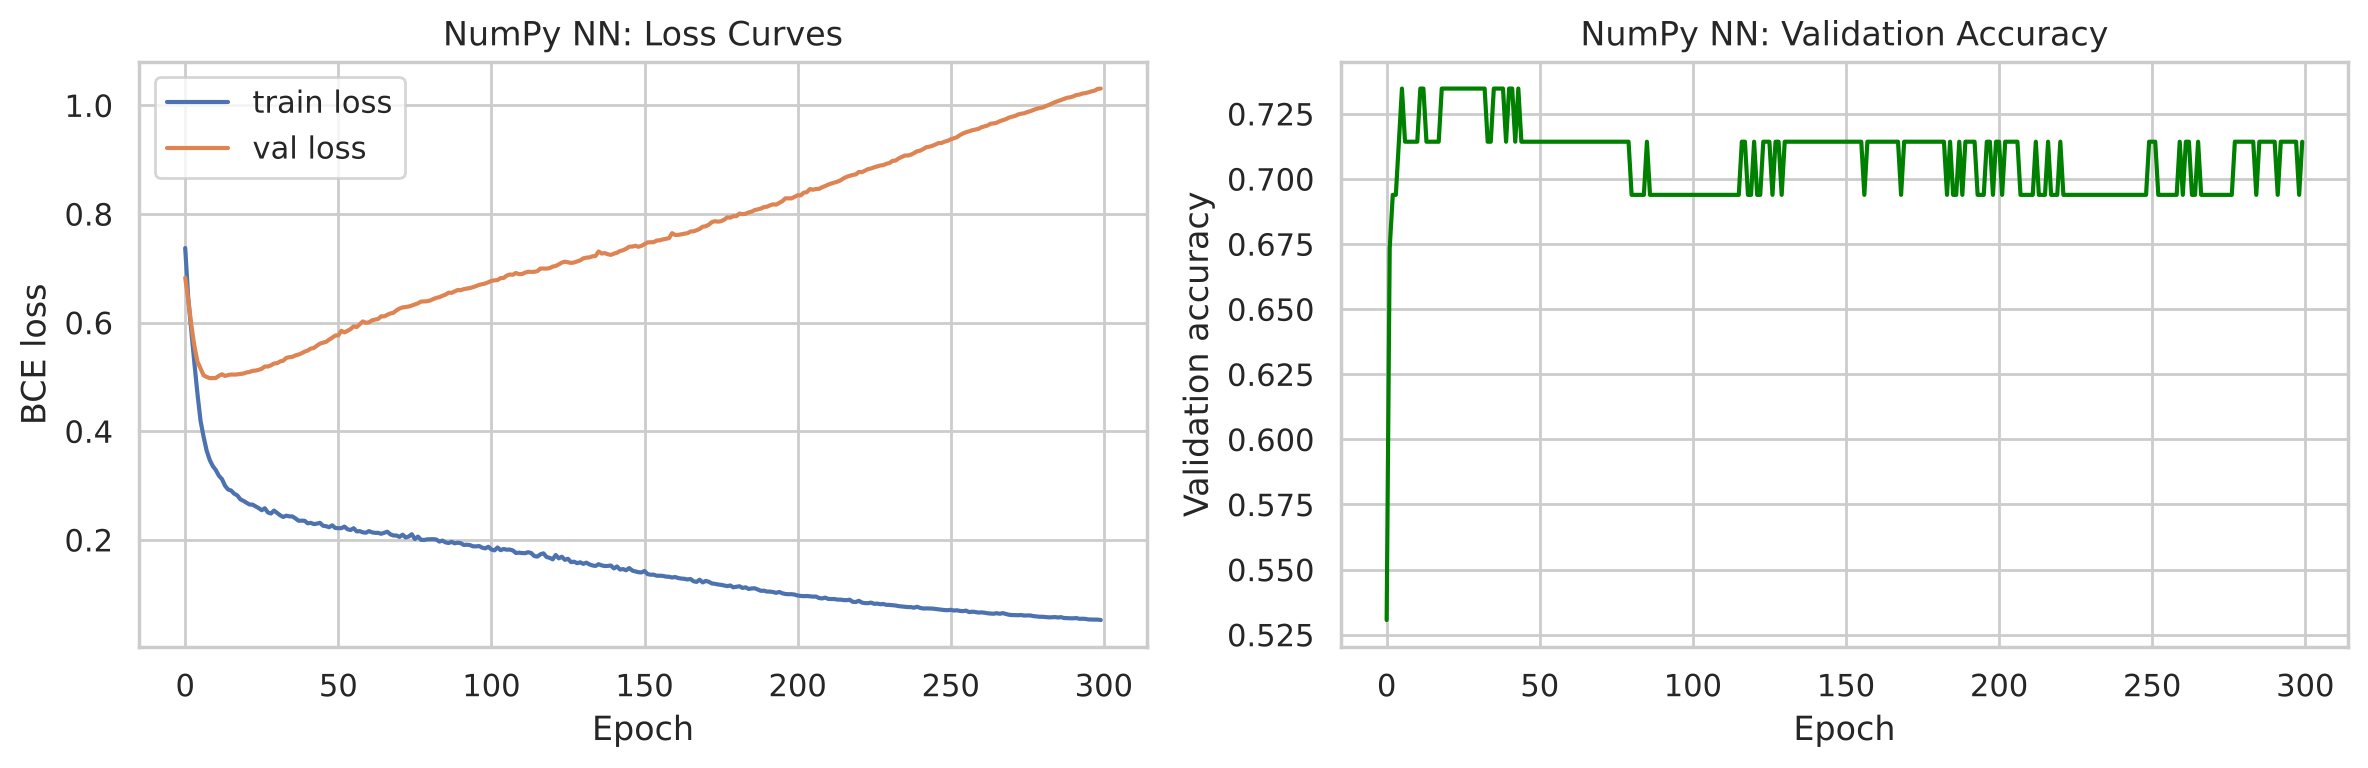

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(numpy_nn_history["loss"], label="train loss")
axes[0].plot(numpy_nn_history["val_loss"], label="val loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE loss"); axes[0].legend()
axes[0].set_title("NumPy NN: Loss Curves")
axes[1].plot(numpy_nn_history["val_acc"], color="green")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("NumPy NN: Validation Accuracy")
plt.tight_layout()
plt.show()

### Evaluating the NumPy neural network

In [16]:
numpy_val_proba = numpy_nn.predict_proba(Xva)
numpy_test_proba = numpy_nn.predict_proba(Xte)
numpy_val_metrics = evaluate_model(yva, numpy_val_proba > 0.5, numpy_val_proba, "NumPy NN (validation)")
numpy_test_metrics = evaluate_model(yte, numpy_test_proba > 0.5, numpy_test_proba, "NumPy NN (test)")

--- NumPy NN (validation) ---
Accuracy: 0.7143 | Precision: 0.7407 | Recall: 0.7407 | F1: 0.7407 | ROC-AUC: 0.8098
--- NumPy NN (test) ---
Accuracy: 0.8525 | Precision: 0.8750 | Recall: 0.8485 | F1: 0.8615 | ROC-AUC: 0.8983


### Insights: NumPy network

- **Results:** the from-scratch network reaches **85.2% test accuracy and 0.898 test ROC-AUC**, with 84.8% recall on patients who have heart disease. On the validation split it scores lower (71.4% accuracy, 0.810 AUC). With only 49 validation and 61 test patients, a handful of patients moves these metrics by several points.
- **Overfitting:** the loss curves show the classic pattern. Training loss keeps falling to about 0.05, but validation loss bottoms out at about 0.50 around epoch 10 and then climbs steadily to about 1.03 by epoch 300. Training for a fixed 300 epochs on 192 patients memorises the training set. Early stopping on validation loss, or L2 regularisation, would be the first fixes.
- **Gradient flow:** using sigmoid in the hidden layer exposes the **vanishing-gradient problem**. The sigmoid derivative peaks at 0.25, so errors shrink every time they are backpropagated through a layer. A single hidden layer still trains, but deeper sigmoid networks would stall near the input.
- **Optimisation:** vanilla gradient descent applies one fixed learning rate to every parameter, so it cannot adapt step sizes for parameters whose gradients are noisy or sparse.
- **Recommendations:** use **ReLU** in the hidden layers to keep a constant gradient of 1 for positive activations, and use an adaptive optimiser such as **Adam**, which tracks running estimates of each parameter's gradient mean and variance. Both are tested in Keras in Part 3.

# Part 3: TensorFlow/Keras Implementation

Two Keras configurations are compared with the NumPy model:
- **Baseline:** two ReLU hidden layers (16 and 8 units) with the Adam optimiser.
- **Alternative:** the same architecture with tanh activations and SGD with momentum.

Both use binary cross-entropy loss, track accuracy and AUC, and stop early when validation loss stops improving.

In [17]:
def build_ffnn(input_dim, activation, name):
    return keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(16, activation=activation),
        layers.Dense(8, activation=activation),
        layers.Dense(1, activation="sigmoid"),
    ], name=name)

def fit_and_score(model, optimizer, epochs=100):
    model.compile(optimizer=optimizer, loss="binary_crossentropy",
                  metrics=["accuracy", metrics.AUC(name="auc")])
    early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    history = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs,
                        batch_size=32, callbacks=[early_stop], verbose=0)
    print(f"{model.name}: trained for {len(history.history['loss'])} epochs")
    return history

keras.utils.set_random_seed(SEED)
keras_baseline = build_ffnn(Xtr.shape[1], "relu", "keras_baseline")
hist_baseline = fit_and_score(keras_baseline, optimizers.Adam(learning_rate=0.001))

keras.utils.set_random_seed(SEED)
keras_alt = build_ffnn(Xtr.shape[1], "tanh", "keras_alt")
hist_alt = fit_and_score(keras_alt, optimizers.SGD(learning_rate=0.01, momentum=0.9))
print(f"Trainable parameters per Keras model: {keras_baseline.count_params()}")

keras_baseline: trained for 36 epochs


keras_alt: trained for 18 epochs
Trainable parameters per Keras model: 593


In [18]:
results = {}
for label, model in [("Keras Baseline (ReLU + Adam)", keras_baseline), ("Keras Alt (tanh + SGD)", keras_alt)]:
    val_p = model.predict(Xva, verbose=0)
    test_p = model.predict(Xte, verbose=0)
    results[label] = (evaluate_model(yva, val_p > 0.5, val_p, f"{label} (validation)"),
                      evaluate_model(yte, test_p > 0.5, test_p, f"{label} (test)"), test_p)

probas = {"NumPy NN (sigmoid + GD)": numpy_test_proba}
rows = [{"model": "NumPy NN (sigmoid + GD)",
         "val_accuracy": numpy_val_metrics["accuracy"], "val_auc": numpy_val_metrics["roc_auc"],
         "test_accuracy": numpy_test_metrics["accuracy"], "test_precision": numpy_test_metrics["precision"],
         "test_recall": numpy_test_metrics["recall"], "test_f1": numpy_test_metrics["f1"],
         "test_auc": numpy_test_metrics["roc_auc"]}]
for label, (v, t, p) in results.items():
    probas[label] = p
    rows.append({"model": label, "val_accuracy": v["accuracy"], "val_auc": v["roc_auc"],
                 "test_accuracy": t["accuracy"], "test_precision": t["precision"],
                 "test_recall": t["recall"], "test_f1": t["f1"], "test_auc": t["roc_auc"]})

comparison = pd.DataFrame(rows)
display(comparison.round(4))

--- Keras Baseline (ReLU + Adam) (validation) ---
Accuracy: 0.7551 | Precision: 0.7778 | Recall: 0.7778 | F1: 0.7778 | ROC-AUC: 0.8434
--- Keras Baseline (ReLU + Adam) (test) ---
Accuracy: 0.8033 | Precision: 0.8621 | Recall: 0.7576 | F1: 0.8065 | ROC-AUC: 0.9080
--- Keras Alt (tanh + SGD) (validation) ---
Accuracy: 0.7551 | Precision: 0.7778 | Recall: 0.7778 | F1: 0.7778 | ROC-AUC: 0.8670
--- Keras Alt (tanh + SGD) (test) ---
Accuracy: 0.8197 | Precision: 0.8929 | Recall: 0.7576 | F1: 0.8197 | ROC-AUC: 0.8961


,model,val_accuracy,val_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc
0,NumPy NN (sigmoid + GD),0.7143,0.8098,0.8525,0.8750,0.8485,0.8615,0.8983
1,Keras Baseline (ReLU + Adam),0.7551,0.8434,0.8033,0.8621,0.7576,0.8065,0.9080
2,Keras Alt (tanh + SGD),0.7551,0.8670,0.8197,0.8929,0.7576,0.8197,0.8961


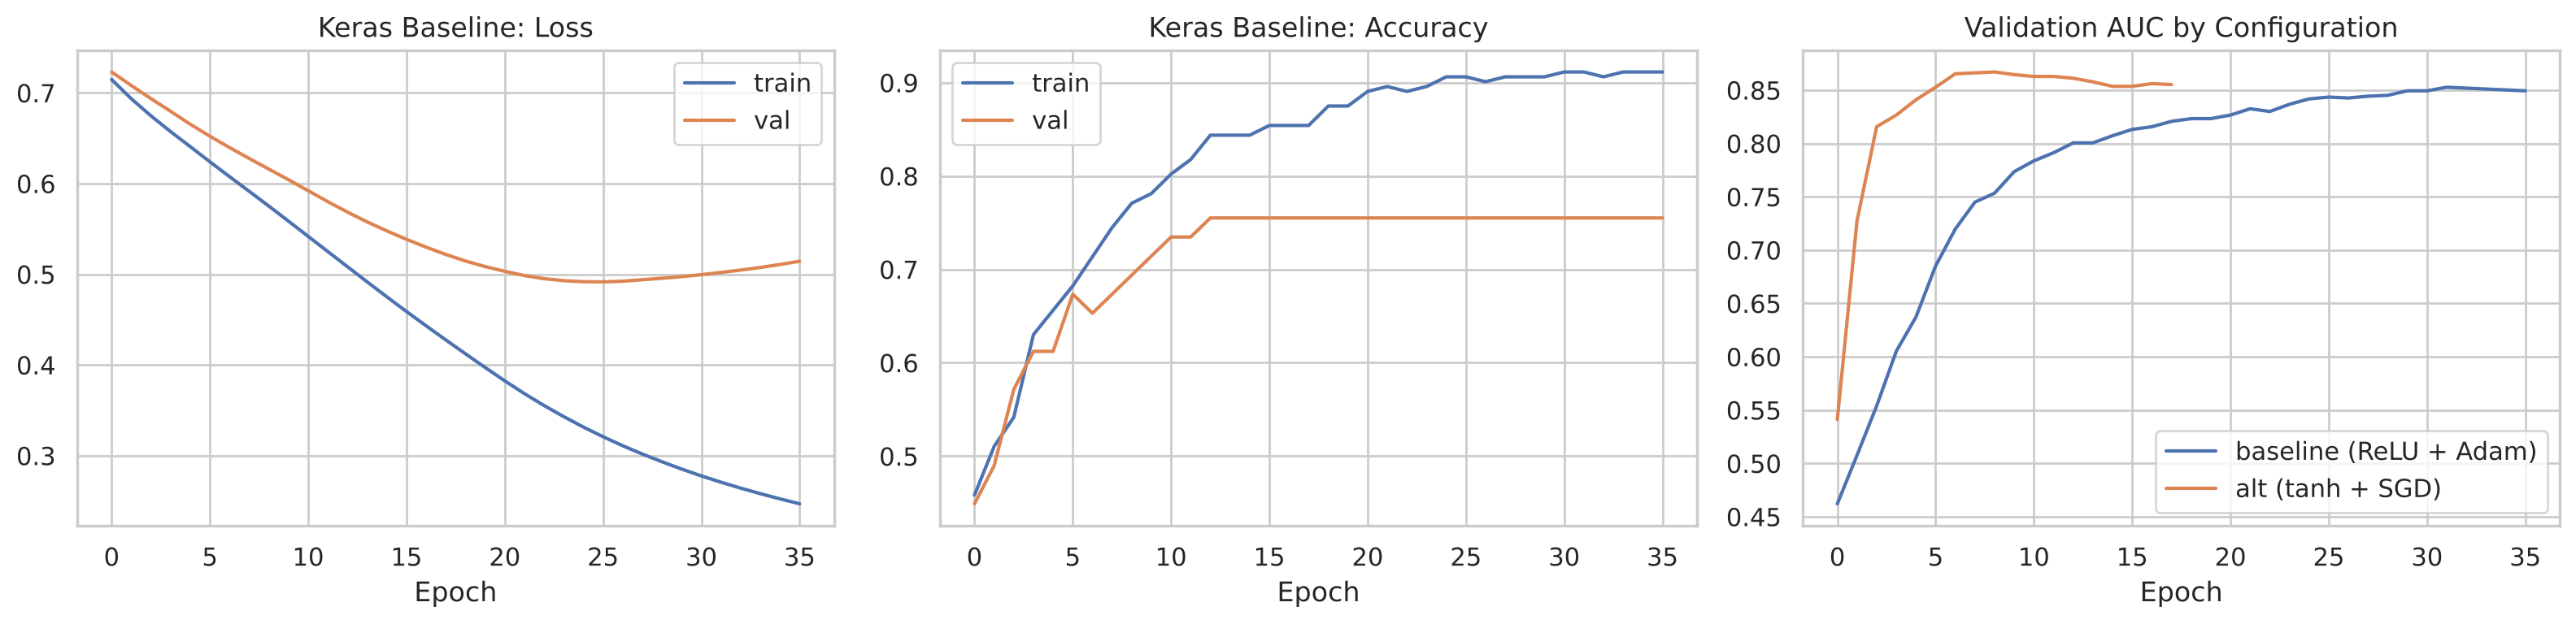

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(hist_baseline.history["loss"], label="train"); axes[0].plot(hist_baseline.history["val_loss"], label="val")
axes[0].set_title("Keras Baseline: Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(hist_baseline.history["accuracy"], label="train"); axes[1].plot(hist_baseline.history["val_accuracy"], label="val")
axes[1].set_title("Keras Baseline: Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
axes[2].plot(hist_baseline.history["val_auc"], label="baseline (ReLU + Adam)")
axes[2].plot(hist_alt.history["val_auc"], label="alt (tanh + SGD)")
axes[2].set_title("Validation AUC by Configuration"); axes[2].set_xlabel("Epoch"); axes[2].legend()
plt.tight_layout()
plt.show()

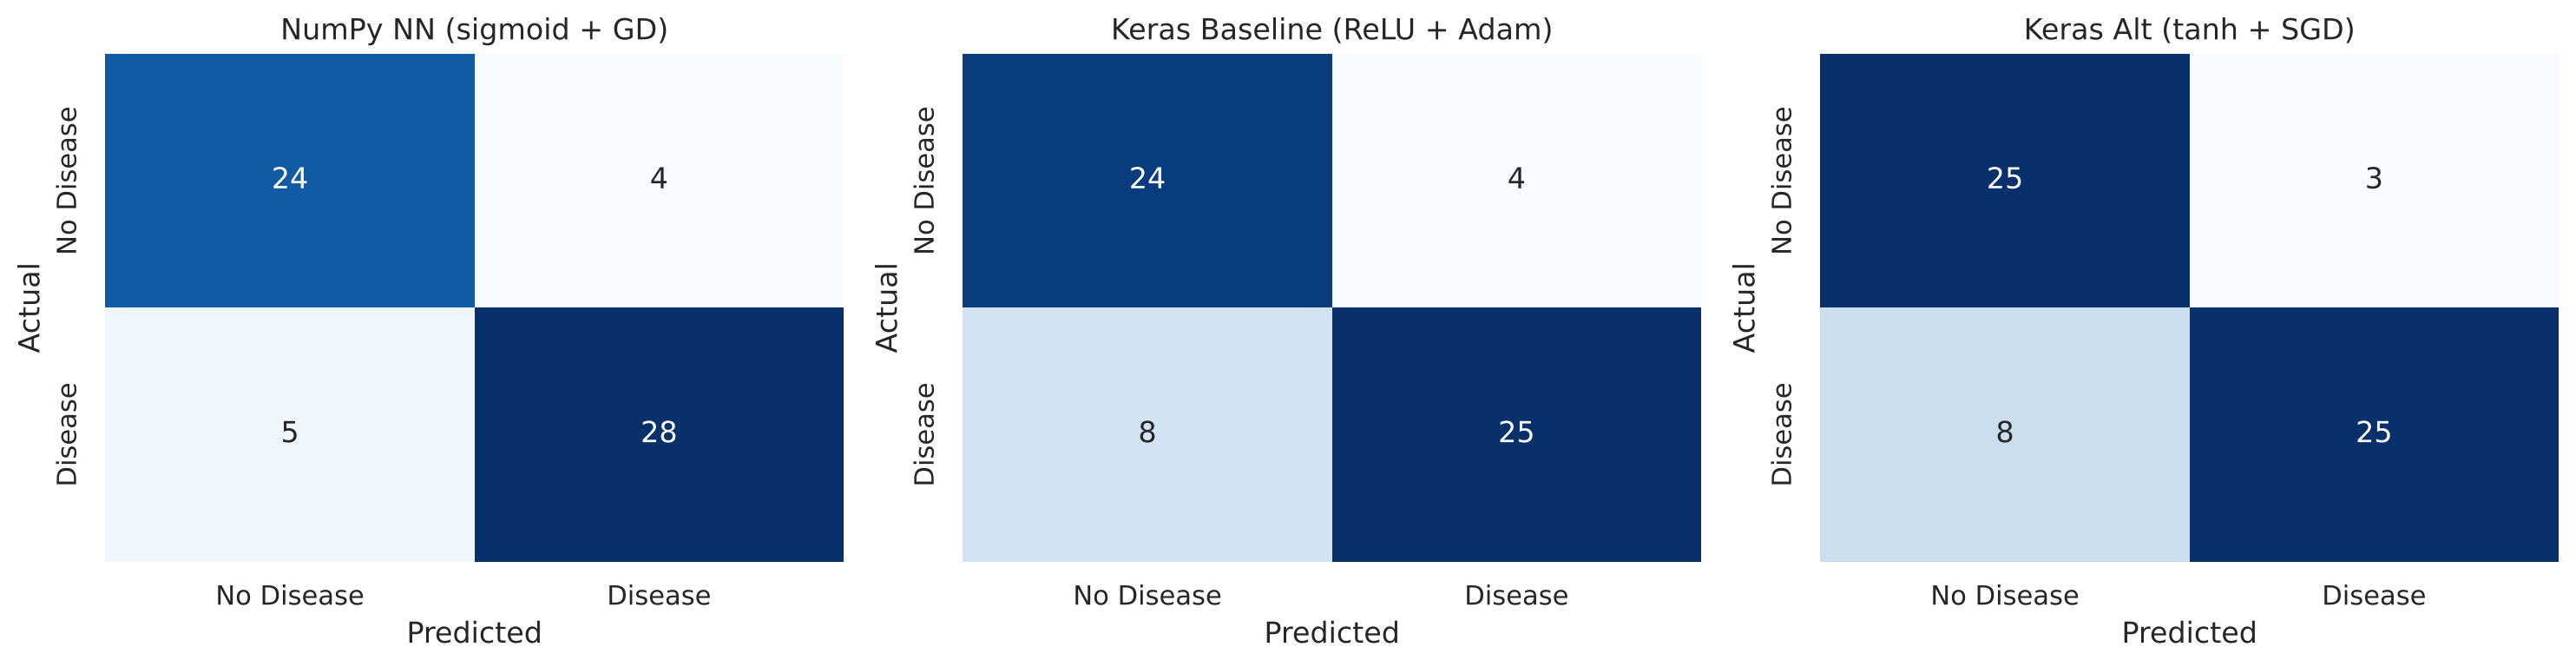

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (label, p) in zip(axes, probas.items()):
    cm = confusion_matrix(yte.ravel(), (np.ravel(p) > 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
    ax.set_title(label); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### Comparison: Keras vs NumPy

| Model | Val accuracy | Val AUC | Test accuracy | Test recall | Test AUC |
| --- | --- | --- | --- | --- | --- |
| NumPy NN (sigmoid + gradient descent) | 0.714 | 0.810 | **0.852** | **0.848** | 0.898 |
| Keras Baseline (ReLU + Adam) | 0.755 | 0.843 | 0.803 | 0.758 | **0.908** |
| Keras Alt (tanh + SGD with momentum) | 0.755 | **0.867** | 0.820 | 0.758 | 0.896 |

- **All three models land in the same band: test ROC-AUC 0.896–0.908.** Once duplicate patients are removed, no implementation clearly dominates. The differences between them are smaller than the noise you would expect from a 61-patient test set.
- **The NumPy network has the best test accuracy and recall.** It misses 5 of 33 disease cases, against 8 for each Keras model. On validation, however, it is the weakest model, and its loss curves show overfitting. Its test lead is therefore not a reliable sign that it is the better model.
- **The Keras models are better calibrated during training.** Early stopping halted the baseline after 36 epochs and the alternative after 18, before validation loss rose. As a result, both have higher validation scores than the NumPy model.
- **ReLU + Adam vs tanh + SGD:** the two Keras configurations finish close together. Adam converges smoothly from a small learning rate, while SGD with momentum reaches its best validation AUC in fewer epochs.
- **Practical takeaway:** Keras gives faster experimentation, built-in early stopping and richer diagnostics. The NumPy implementation gives full transparency into the forward and backward mechanics. For a clinical screening use case, recall on the disease class matters most, so threshold tuning and early stopping would be the next steps for any of these models.

# Part 4: Hyperparameter Analysis

A small grid search over **learning rate (0.01, 0.001) × hidden units (8, 16) × optimiser (Adam, SGD with momentum)** using a single-hidden-layer ReLU network. Each configuration trains briefly (12 epochs), and validation metrics are collected for comparison.

In [21]:
sweep = []
for lr in [0.01, 0.001]:
    for hidden in [8, 16]:
        for opt_name in ["adam", "sgd"]:
            keras.utils.set_random_seed(SEED)
            model = keras.Sequential([
                layers.Input(shape=(Xtr.shape[1],)),
                layers.Dense(hidden, activation="relu"),
                layers.Dense(1, activation="sigmoid"),
            ])
            opt = optimizers.Adam(learning_rate=lr) if opt_name == "adam" else optimizers.SGD(learning_rate=lr, momentum=0.9)
            model.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy", metrics.AUC(name="auc")])
            h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=12, batch_size=32, verbose=0)
            val_loss, val_acc, val_auc = model.evaluate(Xva, yva, verbose=0)
            sweep.append({"lr": lr, "hidden": hidden, "optimizer": opt_name,
                          "val_loss": val_loss, "val_accuracy": val_acc, "val_auc": val_auc,
                          "best_epoch_val_auc": max(h.history["val_auc"])})

df_sweep = pd.DataFrame(sweep).sort_values(["val_auc", "val_loss"], ascending=[False, True]).reset_index(drop=True)
display(df_sweep.round(4))

,lr,hidden,optimizer,val_loss,val_accuracy,val_auc,best_epoch_val_auc
0,0.010,16,adam,0.6051,0.7347,0.8485,0.8485
1,0.010,16,sgd,0.4958,0.7551,0.8476,0.8476
2,0.010,8,adam,0.5617,0.7143,0.8325,0.8443
3,0.010,8,sgd,0.4965,0.7347,0.8258,0.8283
4,0.001,8,adam,0.5356,0.7347,0.8207,0.8207
5,0.001,8,sgd,0.5776,0.6735,0.7904,0.7904
6,0.001,16,adam,0.5713,0.7347,0.7828,0.7828
7,0.001,16,sgd,0.6628,0.6735,0.6625,0.6625


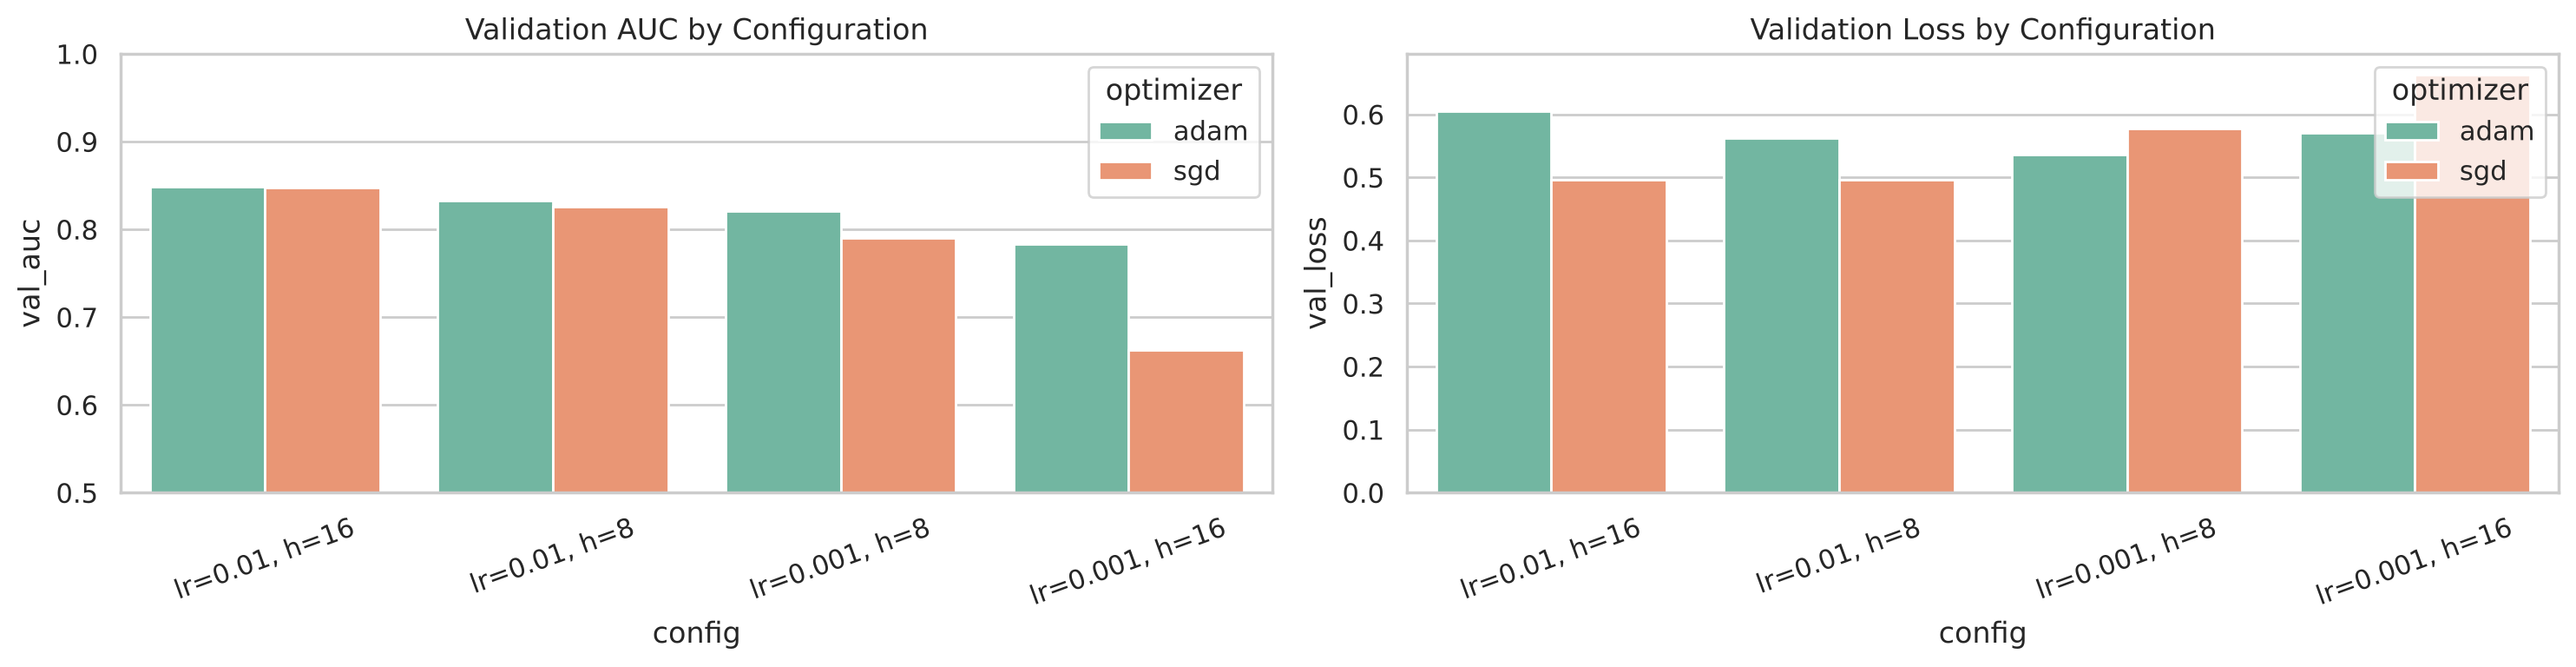

Mean validation AUC by factor:
{'adam': 0.8211, 'sgd': 0.7816}
{0.001: 0.7641, 0.01: 0.8386}
{8: 0.8173, 16: 0.7854}

Mean validation loss by factor:
{'adam': 0.5684, 'sgd': 0.5582}
{0.001: 0.5868, 0.01: 0.5398}
{8: 0.5428, 16: 0.5837}


In [22]:
df_plot = df_sweep.assign(config=lambda d: "lr=" + d["lr"].astype(str) + ", h=" + d["hidden"].astype(str))
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.barplot(data=df_plot, x="config", y="val_auc", hue="optimizer", palette="Set2", ax=axes[0])
axes[0].set_title("Validation AUC by Configuration"); axes[0].set_ylim(0.5, 1); axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=df_plot, x="config", y="val_loss", hue="optimizer", palette="Set2", ax=axes[1])
axes[1].set_title("Validation Loss by Configuration"); axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

print("Mean validation AUC by factor:")
for factor in ["optimizer", "lr", "hidden"]:
    print(df_sweep.groupby(factor)["val_auc"].mean().round(4).to_dict())
print("\nMean validation loss by factor:")
for factor in ["optimizer", "lr", "hidden"]:
    print(df_sweep.groupby(factor)["val_loss"].mean().round(4).to_dict())

### Hyperparameter insights

- **Best configuration:** Adam with a learning rate of **0.01** and **16 hidden units**, reaching a validation ROC-AUC of **0.849**. SGD with the same settings is almost identical (0.848), with a lower validation loss (0.496 vs 0.605).
- **Learning rate had the largest effect.** At 0.01, the mean validation AUC was 0.839, against 0.764 at 0.001. With only 12 epochs, the smaller rate simply does not have time to converge, which is clearest in the weakest run: SGD at 0.001 with 16 units scored an AUC of 0.663.
- **Optimiser:** Adam averaged a higher validation AUC (0.821 vs 0.782). Its per-parameter adaptive steps make faster progress in a short training budget, especially at the low learning rate.
- **Capacity:** 8 hidden units averaged a slightly higher AUC than 16 (0.817 vs 0.785), and a lower validation loss. On only 192 training patients, extra capacity does not help, and it raises the risk of overfitting.
- **Overall:** in this search space, the learning rate and optimiser mattered more than small changes in architecture. With 49 validation patients, differences of a few hundredths in AUC should not be over-interpreted. Cross-validation would give a more stable ranking.

# Summary of Final Performance

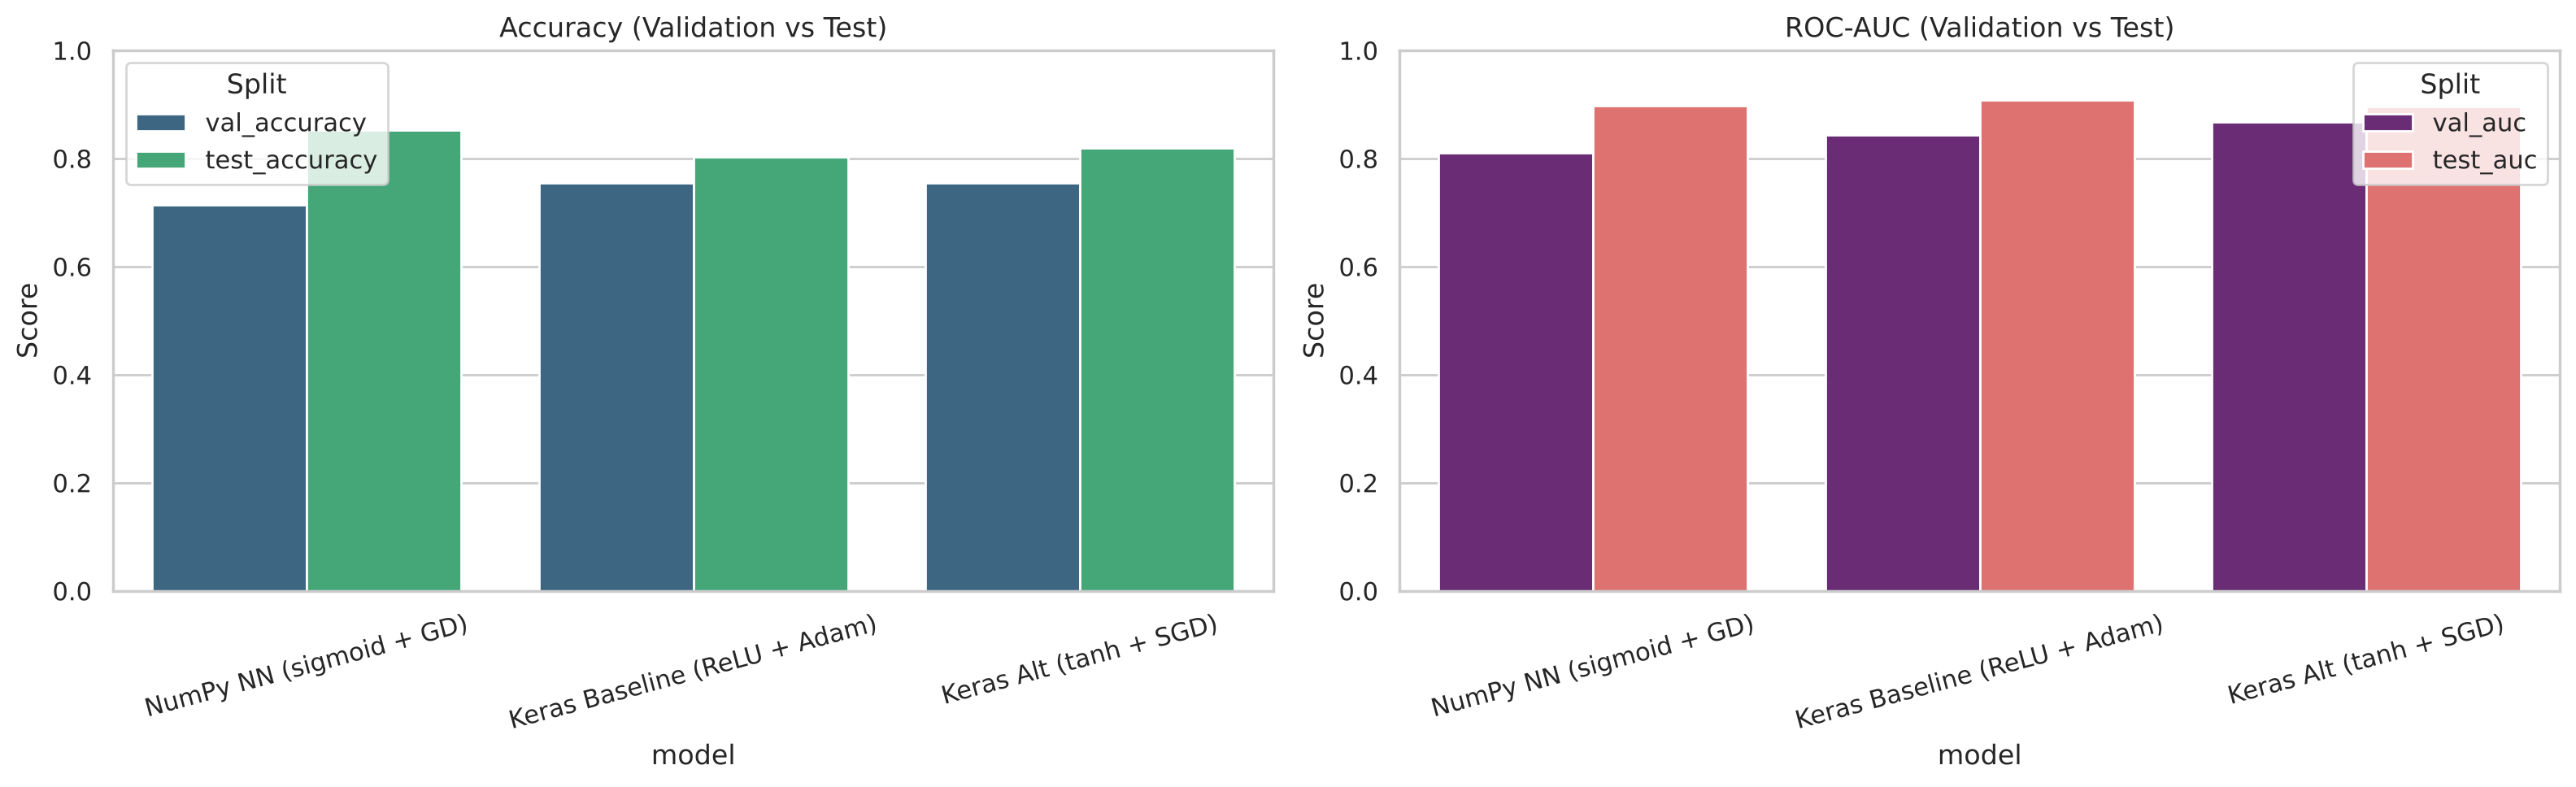

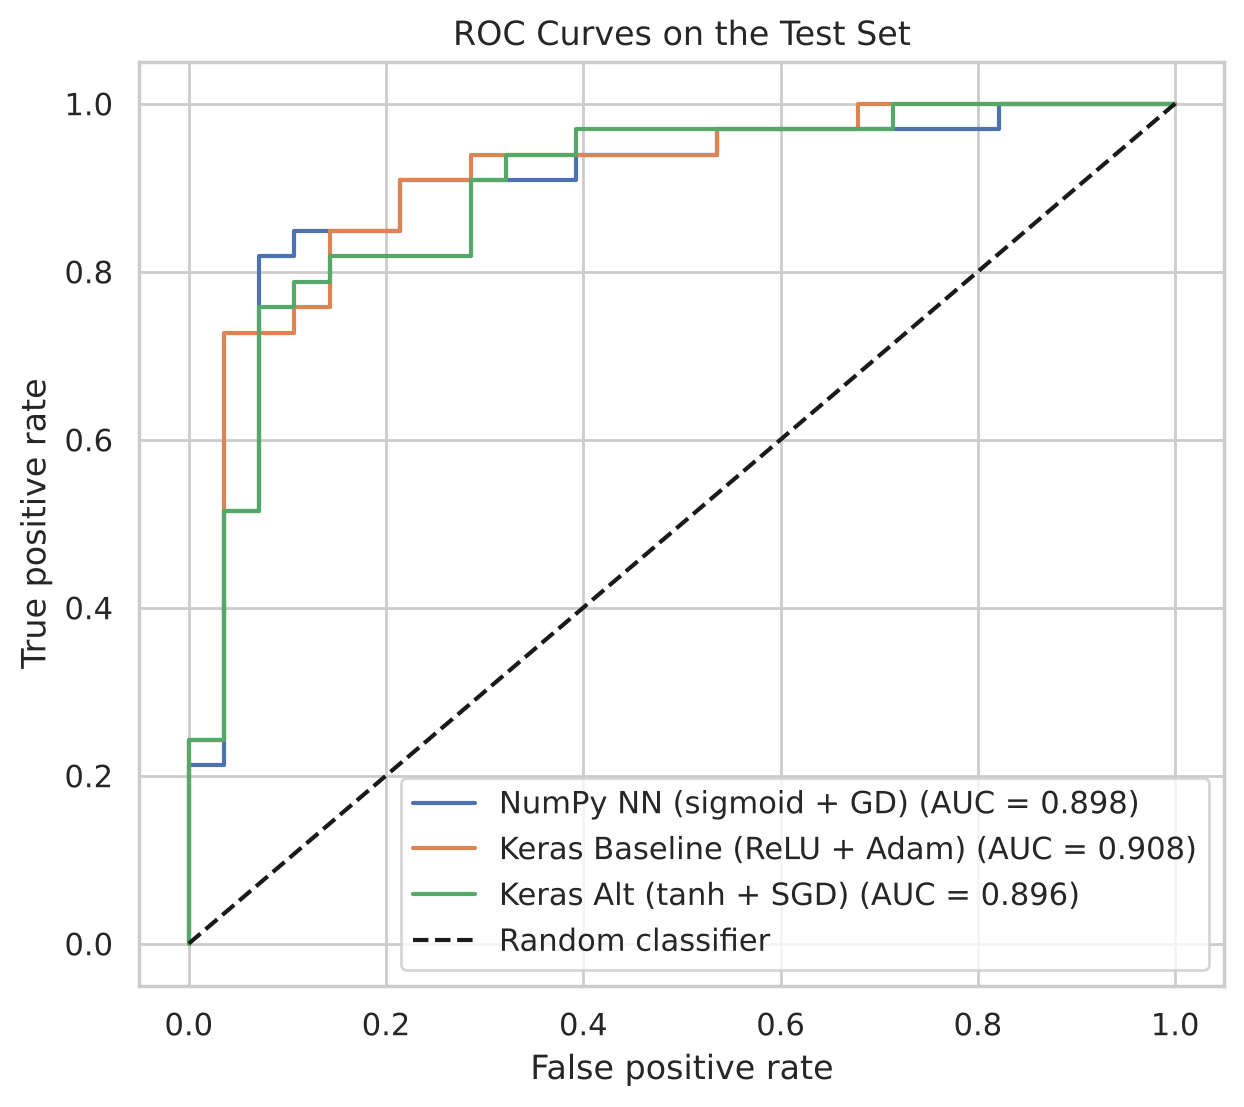

,model,val_accuracy,val_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc
0,NumPy NN (sigmoid + GD),0.7143,0.8098,0.8525,0.8750,0.8485,0.8615,0.8983
1,Keras Baseline (ReLU + Adam),0.7551,0.8434,0.8033,0.8621,0.7576,0.8065,0.9080
2,Keras Alt (tanh + SGD),0.7551,0.8670,0.8197,0.8929,0.7576,0.8197,0.8961


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
acc = comparison[["model", "val_accuracy", "test_accuracy"]].melt(id_vars="model", var_name="Split", value_name="Score")
sns.barplot(data=acc, x="model", y="Score", hue="Split", palette="viridis", ax=axes[0])
axes[0].set_title("Accuracy (Validation vs Test)"); axes[0].set_ylim(0, 1); axes[0].tick_params(axis="x", rotation=15)
auc_df = comparison[["model", "val_auc", "test_auc"]].melt(id_vars="model", var_name="Split", value_name="Score")
sns.barplot(data=auc_df, x="model", y="Score", hue="Split", palette="magma", ax=axes[1])
axes[1].set_title("ROC-AUC (Validation vs Test)"); axes[1].set_ylim(0, 1); axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
for label, p in probas.items():
    fpr, tpr, _ = roc_curve(yte.ravel(), np.ravel(p))
    plt.plot(fpr, tpr, label=f"{label} (AUC = {roc_auc_score(yte.ravel(), np.ravel(p)):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC Curves on the Test Set"); plt.legend(loc="lower right")
plt.show()

display(comparison.round(4))

# Reflection

### 1. Modelling approaches and findings (NumPy vs Keras)

I built and compared two pipelines for heart disease prediction: a neural network written from scratch in NumPy, and higher-level implementations in TensorFlow/Keras.

- **NumPy network:** sigmoid activations in both layers, with forward propagation, binary cross-entropy and backpropagation all implemented by hand. Trained with gradient descent (learning rate 0.5, 300 epochs).
- **Keras Baseline:** ReLU activations with the Adam optimiser.
- **Keras Alternative:** tanh activations with SGD and momentum.
- Both Keras models used early stopping.

The most important finding came before any modelling. **70.5% of the rows in the original file were exact duplicates**, leaving only 302 unique patients. With duplicates kept, copies of the same patient fall into both training and test sets, and an earlier version of this analysis reported a NumPy test AUC of about 0.99. After deduplicating before the split and fitting every preprocessing step on the training data only, the results are more realistic.

Once leakage is removed, all three models score a **test ROC-AUC between 0.896 and 0.908**:

| Model | Test accuracy | Test recall | Test AUC |
| --- | --- | --- | --- |
| NumPy | 0.852 | 0.848 | 0.898 |
| Keras Baseline | 0.803 | 0.758 | 0.908 |
| Keras Alternative | 0.820 | 0.758 | 0.896 |

The NumPy network overfits: its validation loss reaches its lowest point around epoch 10 and rises steadily after that. Early stopping protected the Keras models from the same problem.

### 2. Bias, fairness and ethics concern

A significant concern is **representational imbalance and demographic bias** in clinical data. In the deduplicated data, about 68% of patients are male. Historical disparities in who gets tested and diagnosed can produce diagnostic patterns that fit some patient profiles better than others. That can lead to higher **false negative rates** for under-represented groups, such as women or particular age bands. In healthcare, a missed diagnosis delays treatment, so this is a serious risk.

### 3. How preprocessing and modelling choices influence this concern

- **IQR capping (winsorisation):** stabilises training, but can smooth away genuine, rare clinical extremes. If those extremes are concentrated in a vulnerable subgroup, the model may under-diagnose that group.
- **Global optimisation metrics:** selecting models on overall accuracy or AUC can hide much worse performance in small subgroups. A model can look strong overall while carrying an unacceptable false negative rate for one group.
- **Standardisation and encoding:** these help optimisation but do nothing to correct skewed representation in the raw data, so existing disparities can carry straight through.
- **Data quality:** the duplicate rows show how a data-quality issue can create false confidence. A model that appears near-perfect could be deployed without the scrutiny it needs.

### 4. Mitigation and how to evaluate it

I would put in place a **subgroup evaluation protocol**:

- **Disaggregated metric auditing:** split the test data by sex and age band and report sensitivity, specificity and false negative rate for each group, alongside overall metrics.
- **Threshold calibration:** if a group shows a disproportionately high false negative rate, adjust the decision threshold to move towards **equalised odds**, meaning similar false positive and false negative rates across groups.

**Evaluating effectiveness:**
- Use calibration curves per subgroup to check that predicted risks are trustworthy for everyone.
- Define success as reducing the gap in false negative rates between groups to a predefined tolerance (for example, ΔFNR < 0.05) without materially reducing overall performance.
- With only 61 test patients, subgroup estimates would be very noisy, so the protocol would also require a larger, more diverse cohort or cross-validation.
- Regular audits and review with clinical experts would remain essential.

### 5. Key insight about deep learning fundamentals

Deep learning fundamentals are best learned by moving from first principles to frameworks. Building the network in NumPy made every component concrete: weight initialisation, forward propagation through activation functions, the derivation of binary cross-entropy, and the flow of gradients in backpropagation. That made the Keras models far less of a black box.

The second lesson is that **evaluation discipline matters as much as the model itself**. Deduplicating before splitting and fitting preprocessing on training data only changed the conclusions more than any choice of architecture or optimiser.